# Evaluation: recorded final-test results

Every performance value and interval below comes from closed JSON artifacts. This notebook
reads those records and existing figures, without fitting models, producing predictions,
reopening the final test or recomputing performance. The temporal population contains
non-held-out cells in 2023-2025; the geographic population contains held-out cells in those years.
The target remains selected satellite detections during the following seven days.

Baseline identities were fixed by uncalibrated validation AP. Original baseline probabilities
and calibrated logistic/LightGBM probabilities are retained in primary comparisons. Geographic
results use the separately selected `strict_geo` models, which omit cell climatology.

In [1]:
import json

import pandas as pd
from IPython.display import Markdown, display

from bolivia_fire.config import REPO_ROOT
from bolivia_fire.figures import show_results_figure
from bolivia_fire.firms.storage import sha256_file

root = REPO_ROOT
directory = root / "artifacts/evaluation"
report = json.loads((directory / "test_strict.json").read_text(encoding="utf-8"))
summary = json.loads((root / "artifacts/figures/results_summary.json").read_text(encoding="utf-8"))
log = json.loads((directory / "final_test_log.json").read_text(encoding="utf-8"))
assert report["final_test_opening"] in log
assert (
    sha256_file(directory / "test_strict.json")
    == summary["sources"]["artifacts/evaluation/test_strict.json"]["sha256"]
)
print("Source: artifacts/evaluation/test_strict.json")
print("Temporal selected model:", report["selected_model"])
print("Geographic selected model:", report["geographic_holdout"]["selected_model"])
print("Recorded final-test accesses:", len(log))

Source: artifacts/evaluation/test_strict.json
Temporal selected model: lightgbm_08
Geographic selected model: lightgbm_04
Recorded final-test accesses: 7


## Temporal test and H1

The table retains recorded temporal AP and 95% block-bootstrap endpoints. H1 compares the
calibrated selected strict candidate with the validation-selected original baseline. Its frozen
rule requires the paired AP-difference interval to lie entirely above zero. Monthly blocks,
500 replicates, preserve some temporal dependence; they do not remove all sources of uncertainty.

,AP,95% lower,95% upper,Paired AP difference vs baseline
Model,,,,
Climatology,0.166677,0.105385,0.214274,0.000000
Persistence,0.143290,0.085345,0.186614,-0.023387
Logistic regression (calibrated),0.293042,0.195122,0.353043,0.126366
LightGBM (calibrated),0.323393,0.221655,0.382973,0.156716


,Meets frozen rule,95% lower,95% upper,Reason if undefined
Hypothesis,,,,
H1,True,0.099838,0.217886,None
H2,True,-0.004107,0.001889,None


Temporal test, strict; 2023–2025. Original baseline probabilities; fitted candidates are calibrated. Points are recorded APs; differences subtract recorded APs on identical support. 95% paired calendar-month-block bootstrap intervals use 500 recorded replicates. Comparator: Climatology (chosen on val_select).

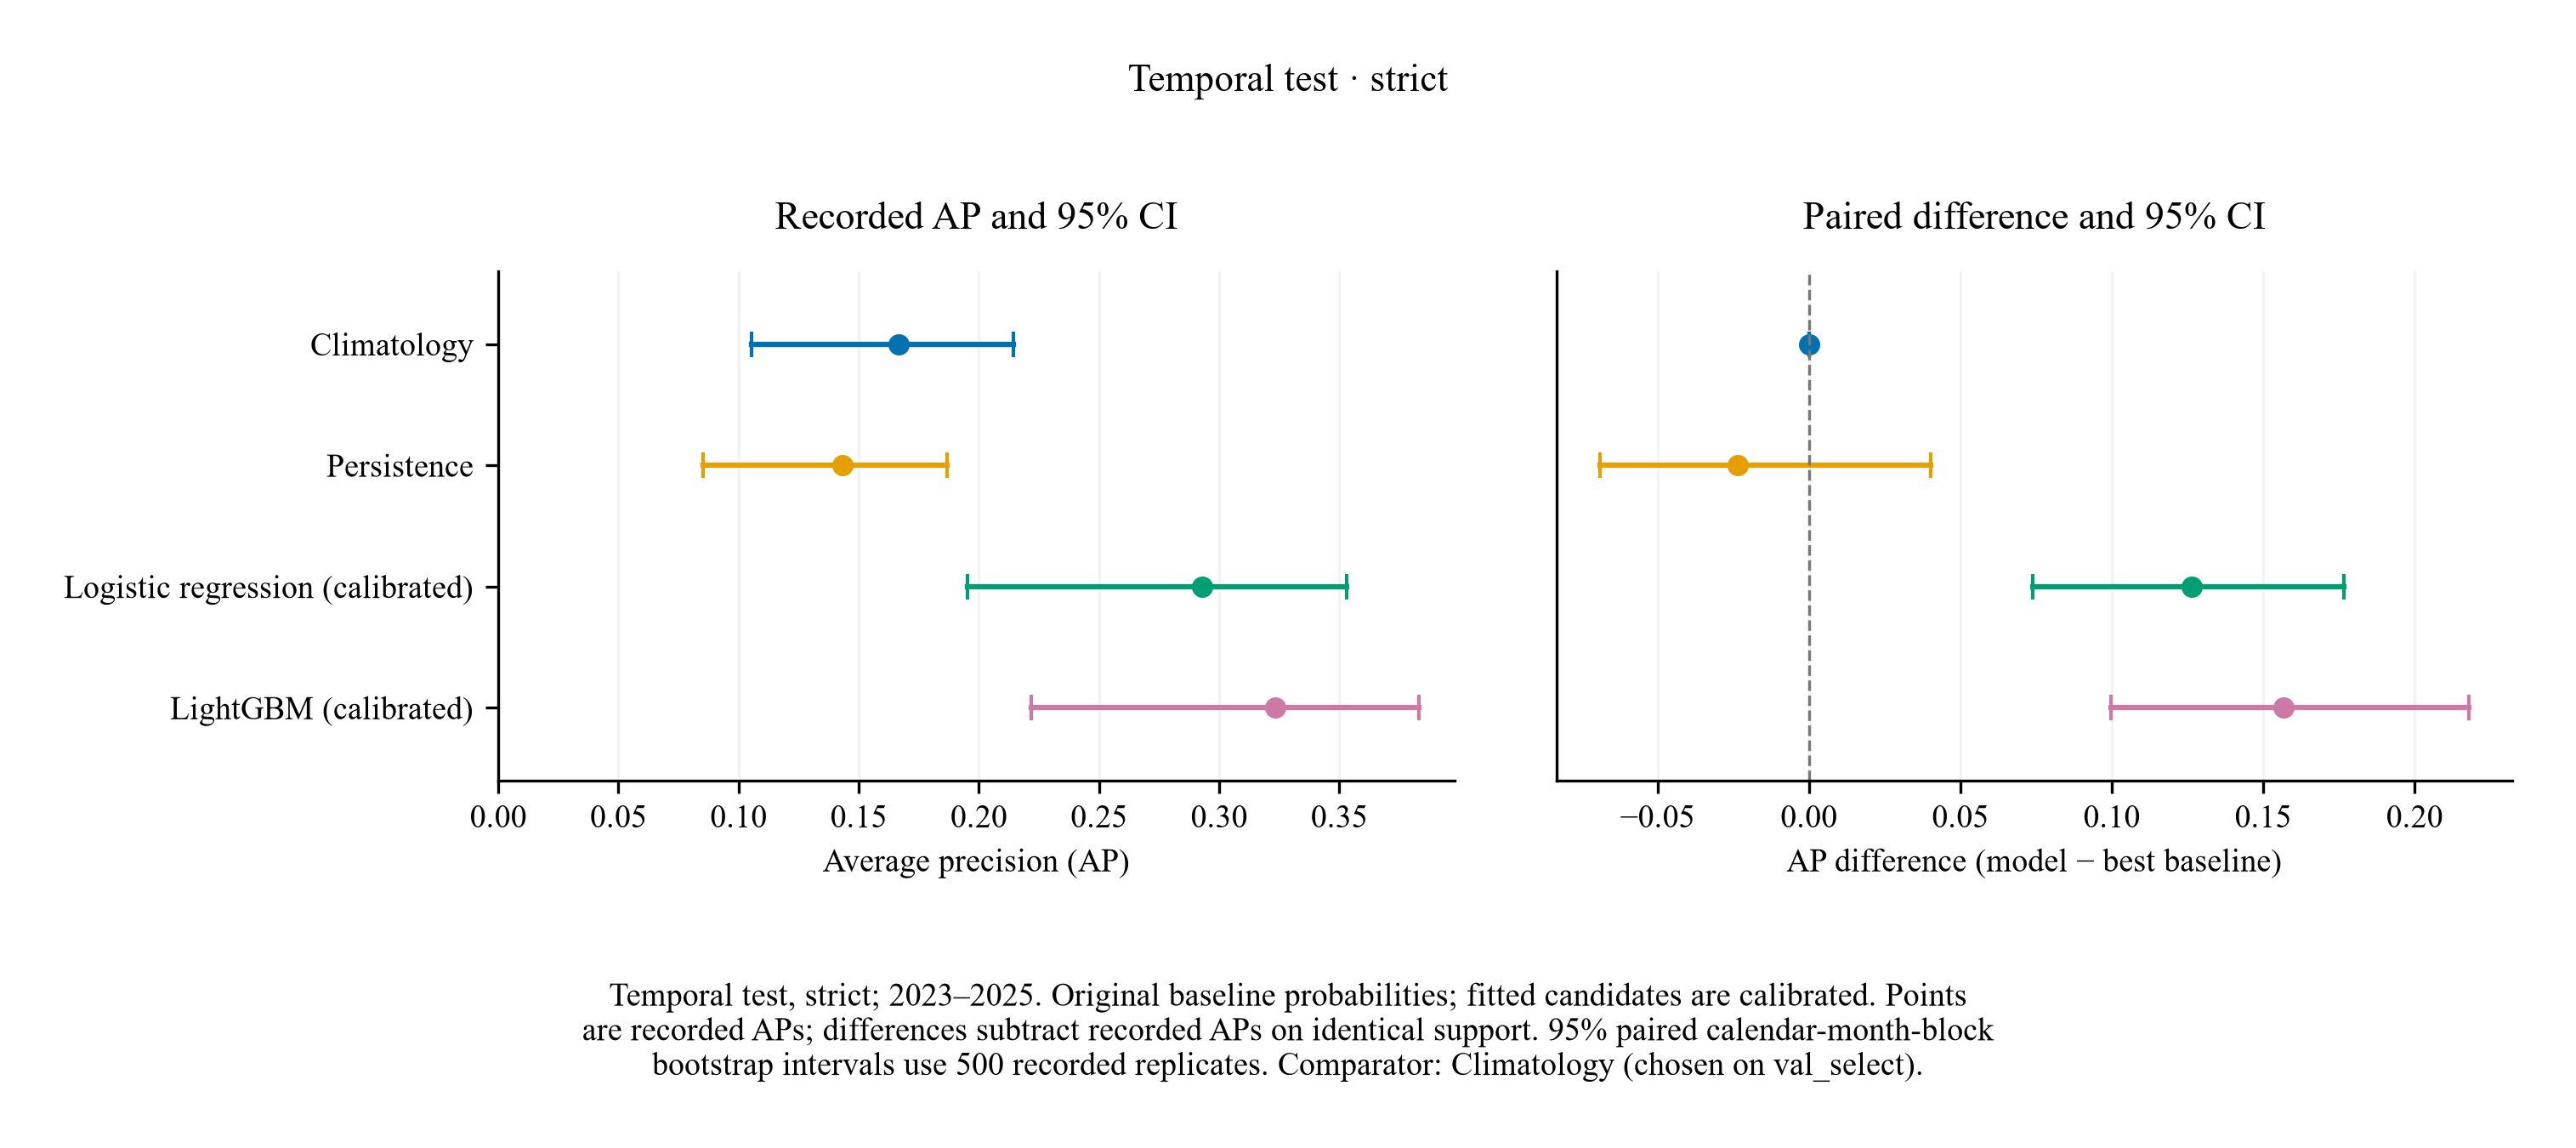

In [2]:
display(
    pd.DataFrame(
        [
            {
                "Model": row["label"],
                "AP": row["average_precision"],
                "95% lower": row["ap_interval"]["lower"],
                "95% upper": row["ap_interval"]["upper"],
                "Paired AP difference vs baseline": row["paired_difference"],
            }
            for row in summary["figures"]["temporal"]["models"]
        ]
    ).set_index("Model")
)
display(
    pd.DataFrame(
        [
            {
                "Hypothesis": name,
                "Meets frozen rule": value["supported"],
                "95% lower": value["interval"]["lower"],
                "95% upper": value["interval"]["upper"],
                "Reason if undefined": value["reason"],
            }
            for name, value in report["hypotheses"].items()
        ]
    ).set_index("Hypothesis")
)
display(Markdown(summary["figures"]["temporal"]["caption"]))
show_results_figure("temporal")

## Calibration

The selected model and best baseline use the recorded equal-frequency reliability bins. The
second panel expands the low-probability range. Missing or undefined bins retain their recorded
status. Brier score, log loss and ECE accompany ranking metrics because AP alone does not measure
probability accuracy. Calibrators were fitted on 2022, before this temporal population.

,Probability,AP,Brier,Log loss,ROC AUC,ECE,Recall 5%,Recall 10%,Rows,Missing p
Model,,,,,,,,,,
train_climatology,uncalibrated,0.166677,0.017580,0.107625,0.829648,0.007013,0.251441,0.397374,3127636,0
persistence,uncalibrated,0.143290,0.017225,0.082888,0.648148,0.010927,0.265362,0.322522,3127636,0
logistic_regression,calibrated,0.293042,0.015900,0.063911,0.923338,0.003878,0.369967,0.544833,3127636,0
lightgbm_08,calibrated,0.323393,0.015533,0.062067,0.927621,0.003132,0.384318,0.557699,3127636,0


Temporal test, 2023–2025. Recorded equal-frequency reliability bins; each point retains its recorded bin mass. The second panel expands the low-probability range; the dashed line is perfect reliability.

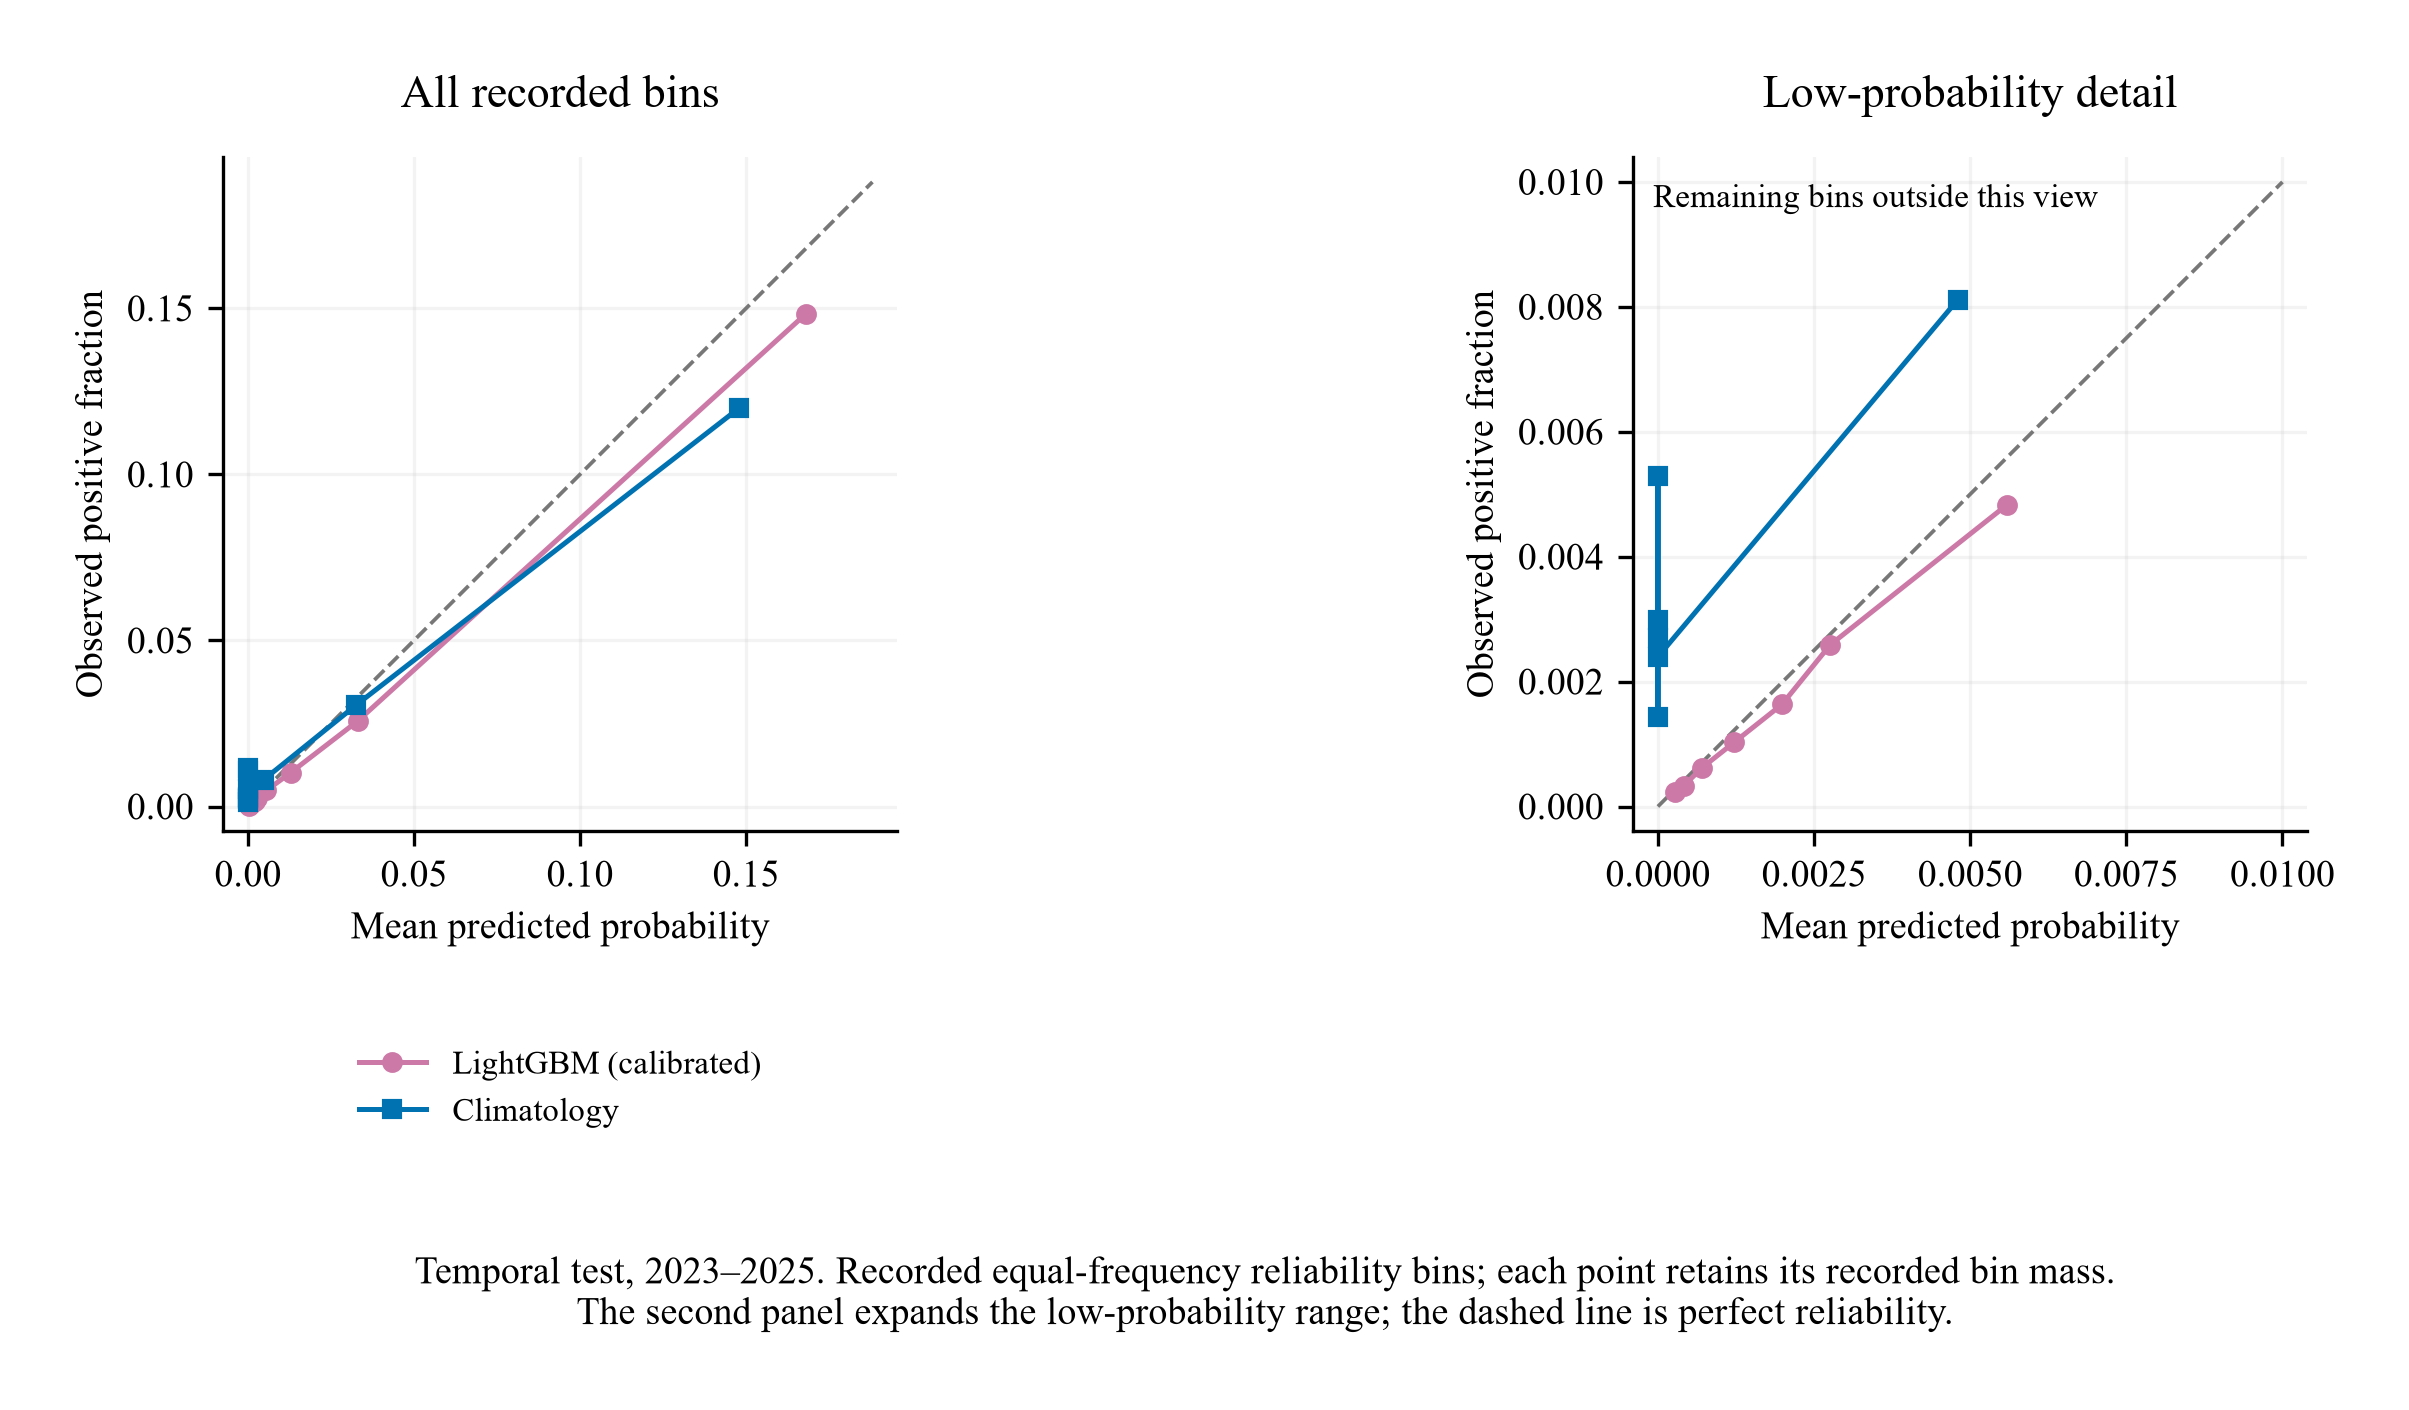

In [3]:
metric_labels = {
    "average_precision": "AP",
    "brier_score": "Brier",
    "log_loss": "Log loss",
    "roc_auc": "ROC AUC",
    "expected_calibration_error": "ECE",
    "recall_at_area_budget_5pct": "Recall 5%",
    "recall_at_area_budget_10pct": "Recall 10%",
    "rows": "Rows",
    "missing_probability": "Missing p",
}
metric_names = [
    "average_precision",
    "brier_score",
    "log_loss",
    "roc_auc",
    "expected_calibration_error",
    "recall_at_area_budget_5pct",
    "recall_at_area_budget_10pct",
    "rows",
    "missing_probability",
]
final_names = [
    report["best_baseline"],
    "persistence",
    "logistic_regression",
    report["selected_model"],
]
final_names = list(dict.fromkeys(final_names))
display(
    pd.DataFrame(
        [
            {
                "Model": name,
                "Probability": version,
                **{key: report["models"][name][version].get(key) for key in metric_names},
            }
            for name in final_names
            for version in (
                ["uncalibrated"] if name in ["train_climatology", "persistence"] else ["calibrated"]
            )
        ]
    )
    .rename(columns=metric_labels)
    .set_index("Model")
)
display(Markdown(summary["figures"]["reliability"]["caption"]))
show_results_figure("reliability")

## Per-year results and Santa Cruz

Annual values and the Santa Cruz restriction are descriptive subgroup reports on the fixed
selected models. No model is reselected for a year or department. Annual intervals are not
recorded. Santa Cruz uses the temporal population restricted to its department cells.

,year,label,probability_version,average_precision
0,2023,Climatology,uncalibrated,0.208612
1,2023,Persistence,uncalibrated,0.155952
2,2023,Logistic regression (calibrated),calibrated,0.332315
3,2023,LightGBM (calibrated),calibrated,0.346671
4,2024,Climatology,uncalibrated,0.099630
5,2024,Persistence,uncalibrated,0.208314
6,2024,Logistic regression (calibrated),calibrated,0.318806
7,2024,LightGBM (calibrated),calibrated,0.373736
8,2025,Climatology,uncalibrated,0.166328
9,2025,Persistence,uncalibrated,0.083709


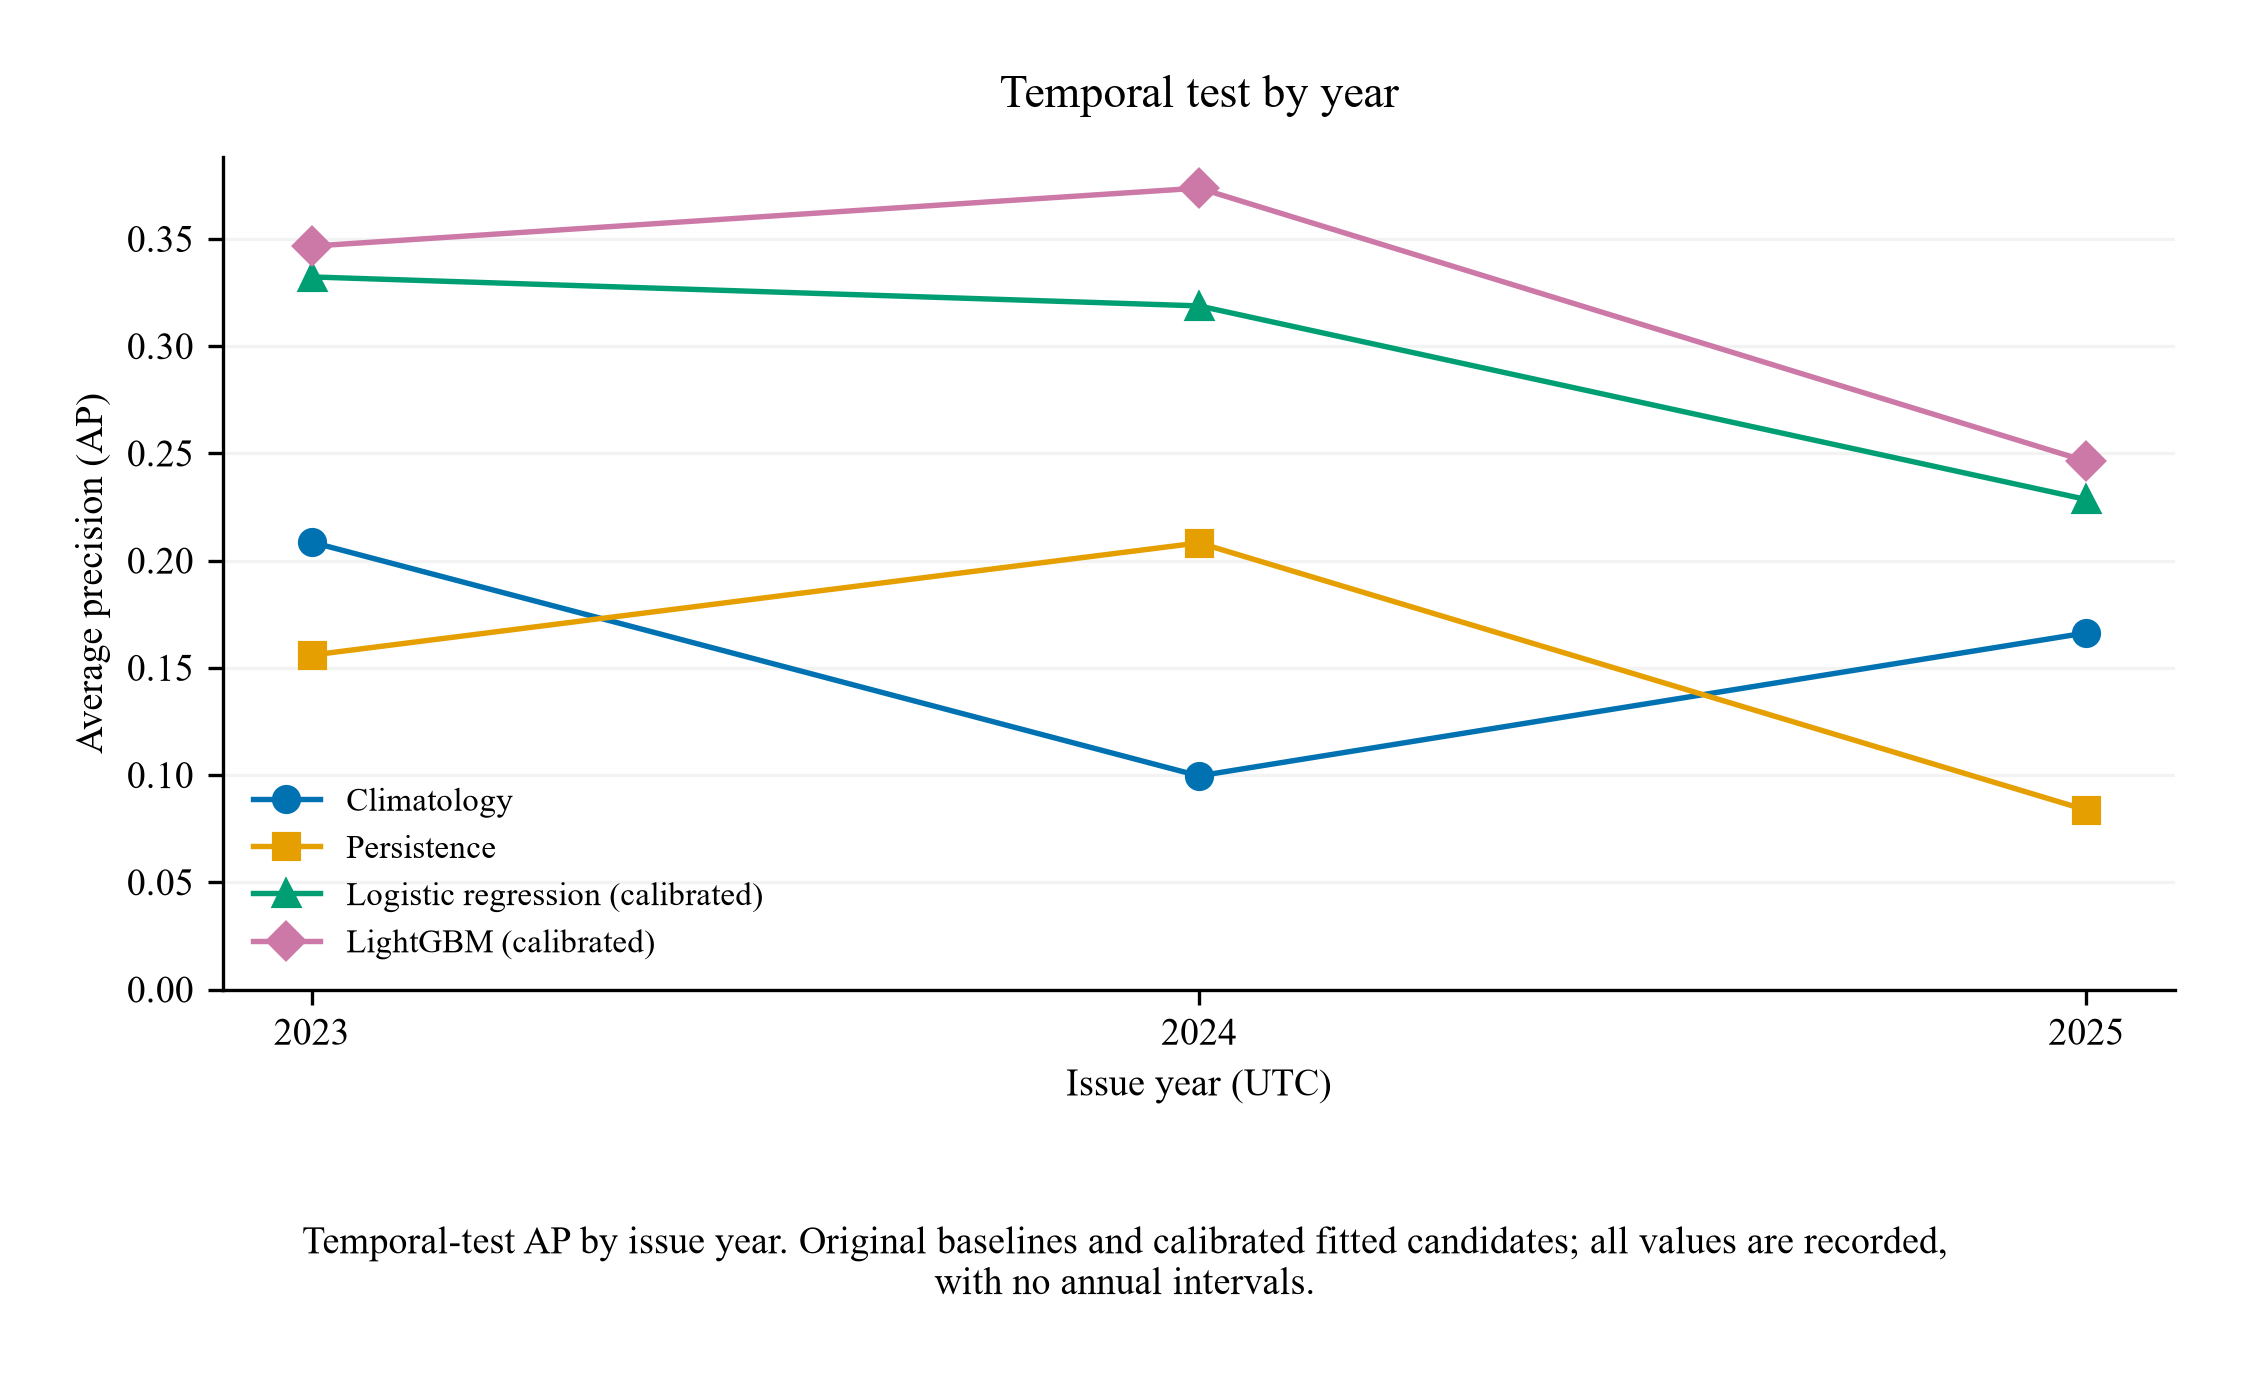

,Probability,AP,Brier,Log loss,ROC AUC,ECE,Recall 5%,Recall 10%,Rows,Missing p
Model,,,,,,,,,,
train_climatology,uncalibrated,0.161291,0.022136,0.146566,0.790540,0.011712,0.215629,0.353170,1095934,0
persistence,uncalibrated,0.201772,0.020462,0.094111,0.680147,0.012715,0.294971,0.366773,1095934,0
logistic_regression,calibrated,0.332745,0.019132,0.075369,0.921797,0.004489,0.372504,0.557984,1095934,0
lightgbm_08,calibrated,0.380798,0.018364,0.072233,0.927228,0.003777,0.388074,0.572590,1095934,0


In [4]:
display(
    pd.DataFrame(summary["figures"]["per_year"]["values"])[
        ["year", "label", "probability_version", "average_precision"]
    ]
)
show_results_figure("per_year")
santa_rows = []
for name, versions in report["santa_cruz"].items():
    version = "uncalibrated" if name in ["train_climatology", "persistence"] else "calibrated"
    metrics = versions[version]
    santa_rows.append(
        {"Model": name, "Probability": version, **{key: metrics.get(key) for key in metric_names}}
    )
display(pd.DataFrame(santa_rows).rename(columns=metric_labels).set_index("Model"))

## Geographic holdout

These are spatiotemporal results on held-out one-degree blocks in the same three years.
The geographic models were independently selected using non-held-out validation cells and
exclude cell climatology. Spatial bootstrap blocks, rather than calendar months, define the
reported geographic uncertainty. The two populations and model variants should not be treated
as the same experiment.

,AP,95% lower,95% upper,Paired AP difference vs baseline
Model,,,,
Climatology,0.070585,0.030861,0.134639,-0.110172
Persistence,0.180757,0.102250,0.243008,0.000000
Logistic regression (calibrated),0.350909,0.218061,0.436205,0.170152
LightGBM (calibrated),0.383912,0.250128,0.467940,0.203154


Geographic holdout, strict_geo; 2023–2025. Original baseline probabilities; fitted candidates are calibrated. Points are recorded APs; differences subtract recorded APs on identical support. 95% paired one-degree spatial-block bootstrap intervals use 500 recorded replicates. Comparator: Persistence (chosen on val_select).

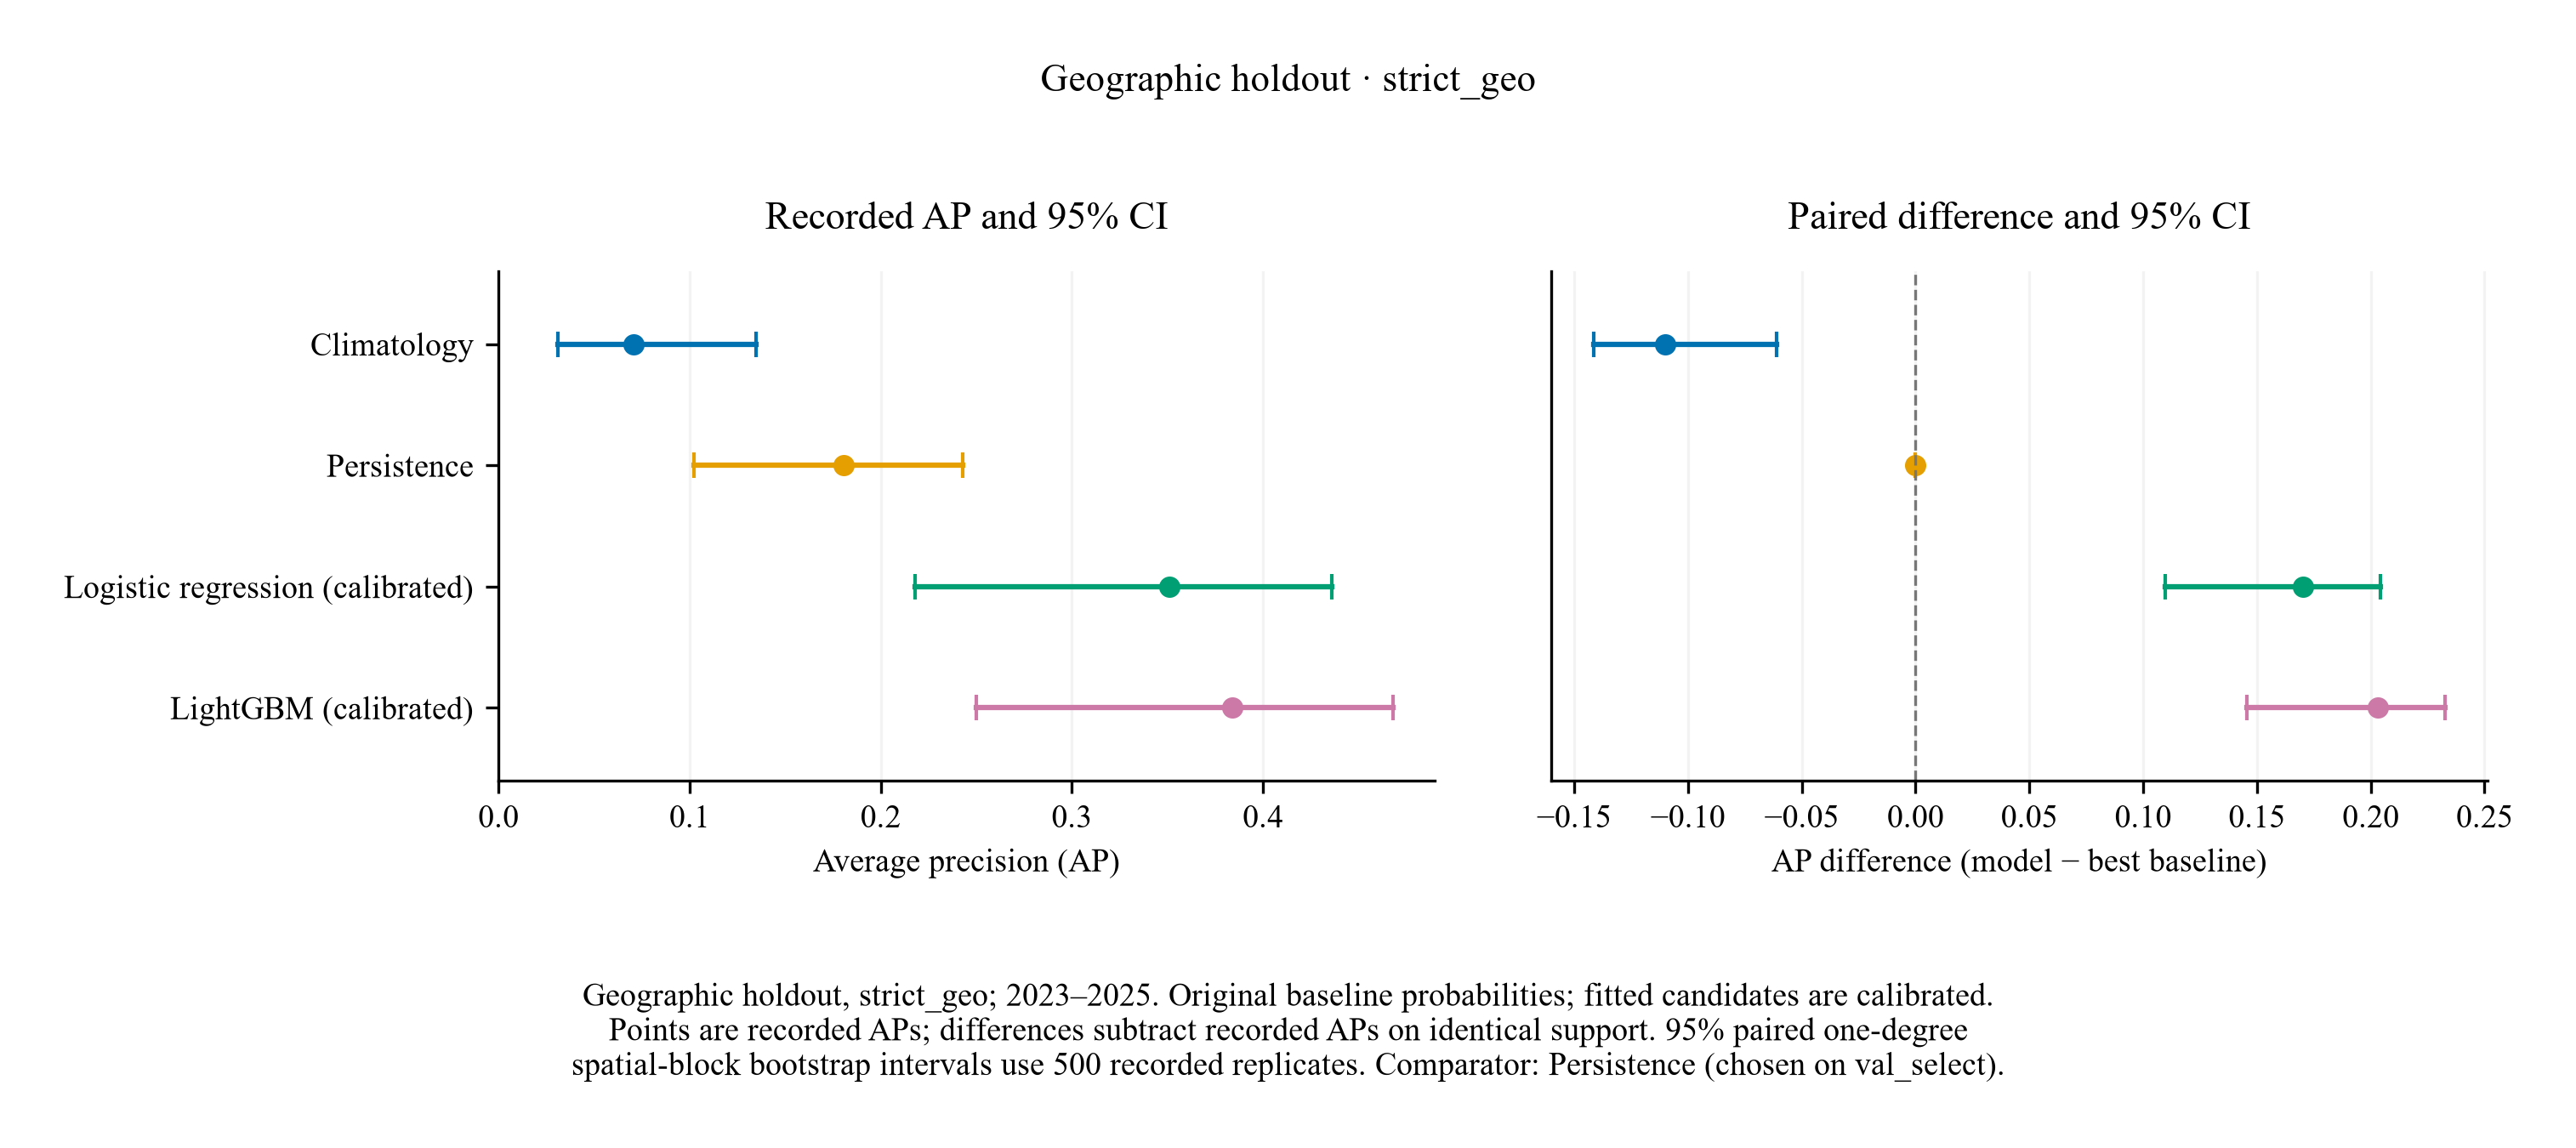

In [5]:
display(
    pd.DataFrame(
        [
            {
                "Model": row["label"],
                "AP": row["average_precision"],
                "95% lower": row["ap_interval"]["lower"],
                "95% upper": row["ap_interval"]["upper"],
                "Paired AP difference vs baseline": row["paired_difference"],
            }
            for row in summary["figures"]["geographic"]["models"]
        ]
    ).set_index("Model")
)
display(Markdown(summary["figures"]["geographic"]["caption"]))
show_results_figure("geographic")

## Recall under weekly area budgets

Each issue ranks cells by probability and allocates 5% or 10% of the eligible national cell
area. The crossing cell contributes fractionally. Positive contributions are pooled over weeks;
a region uses that region's eligible cell area as denominator. These are area budgets rather
than fixed cell counts or intervention recommendations.

,Population,label,area_budget_pct,recall
0,temporal,Climatology,5,0.251441
1,temporal,Climatology,10,0.397374
2,temporal,Persistence,5,0.265362
3,temporal,Persistence,10,0.322522
4,temporal,Logistic regression (calibrated),5,0.369967
5,temporal,Logistic regression (calibrated),10,0.544833
6,temporal,LightGBM (calibrated),5,0.384318
7,temporal,LightGBM (calibrated),10,0.557699
8,geographic,Climatology,5,0.103675
9,geographic,Climatology,10,0.121960


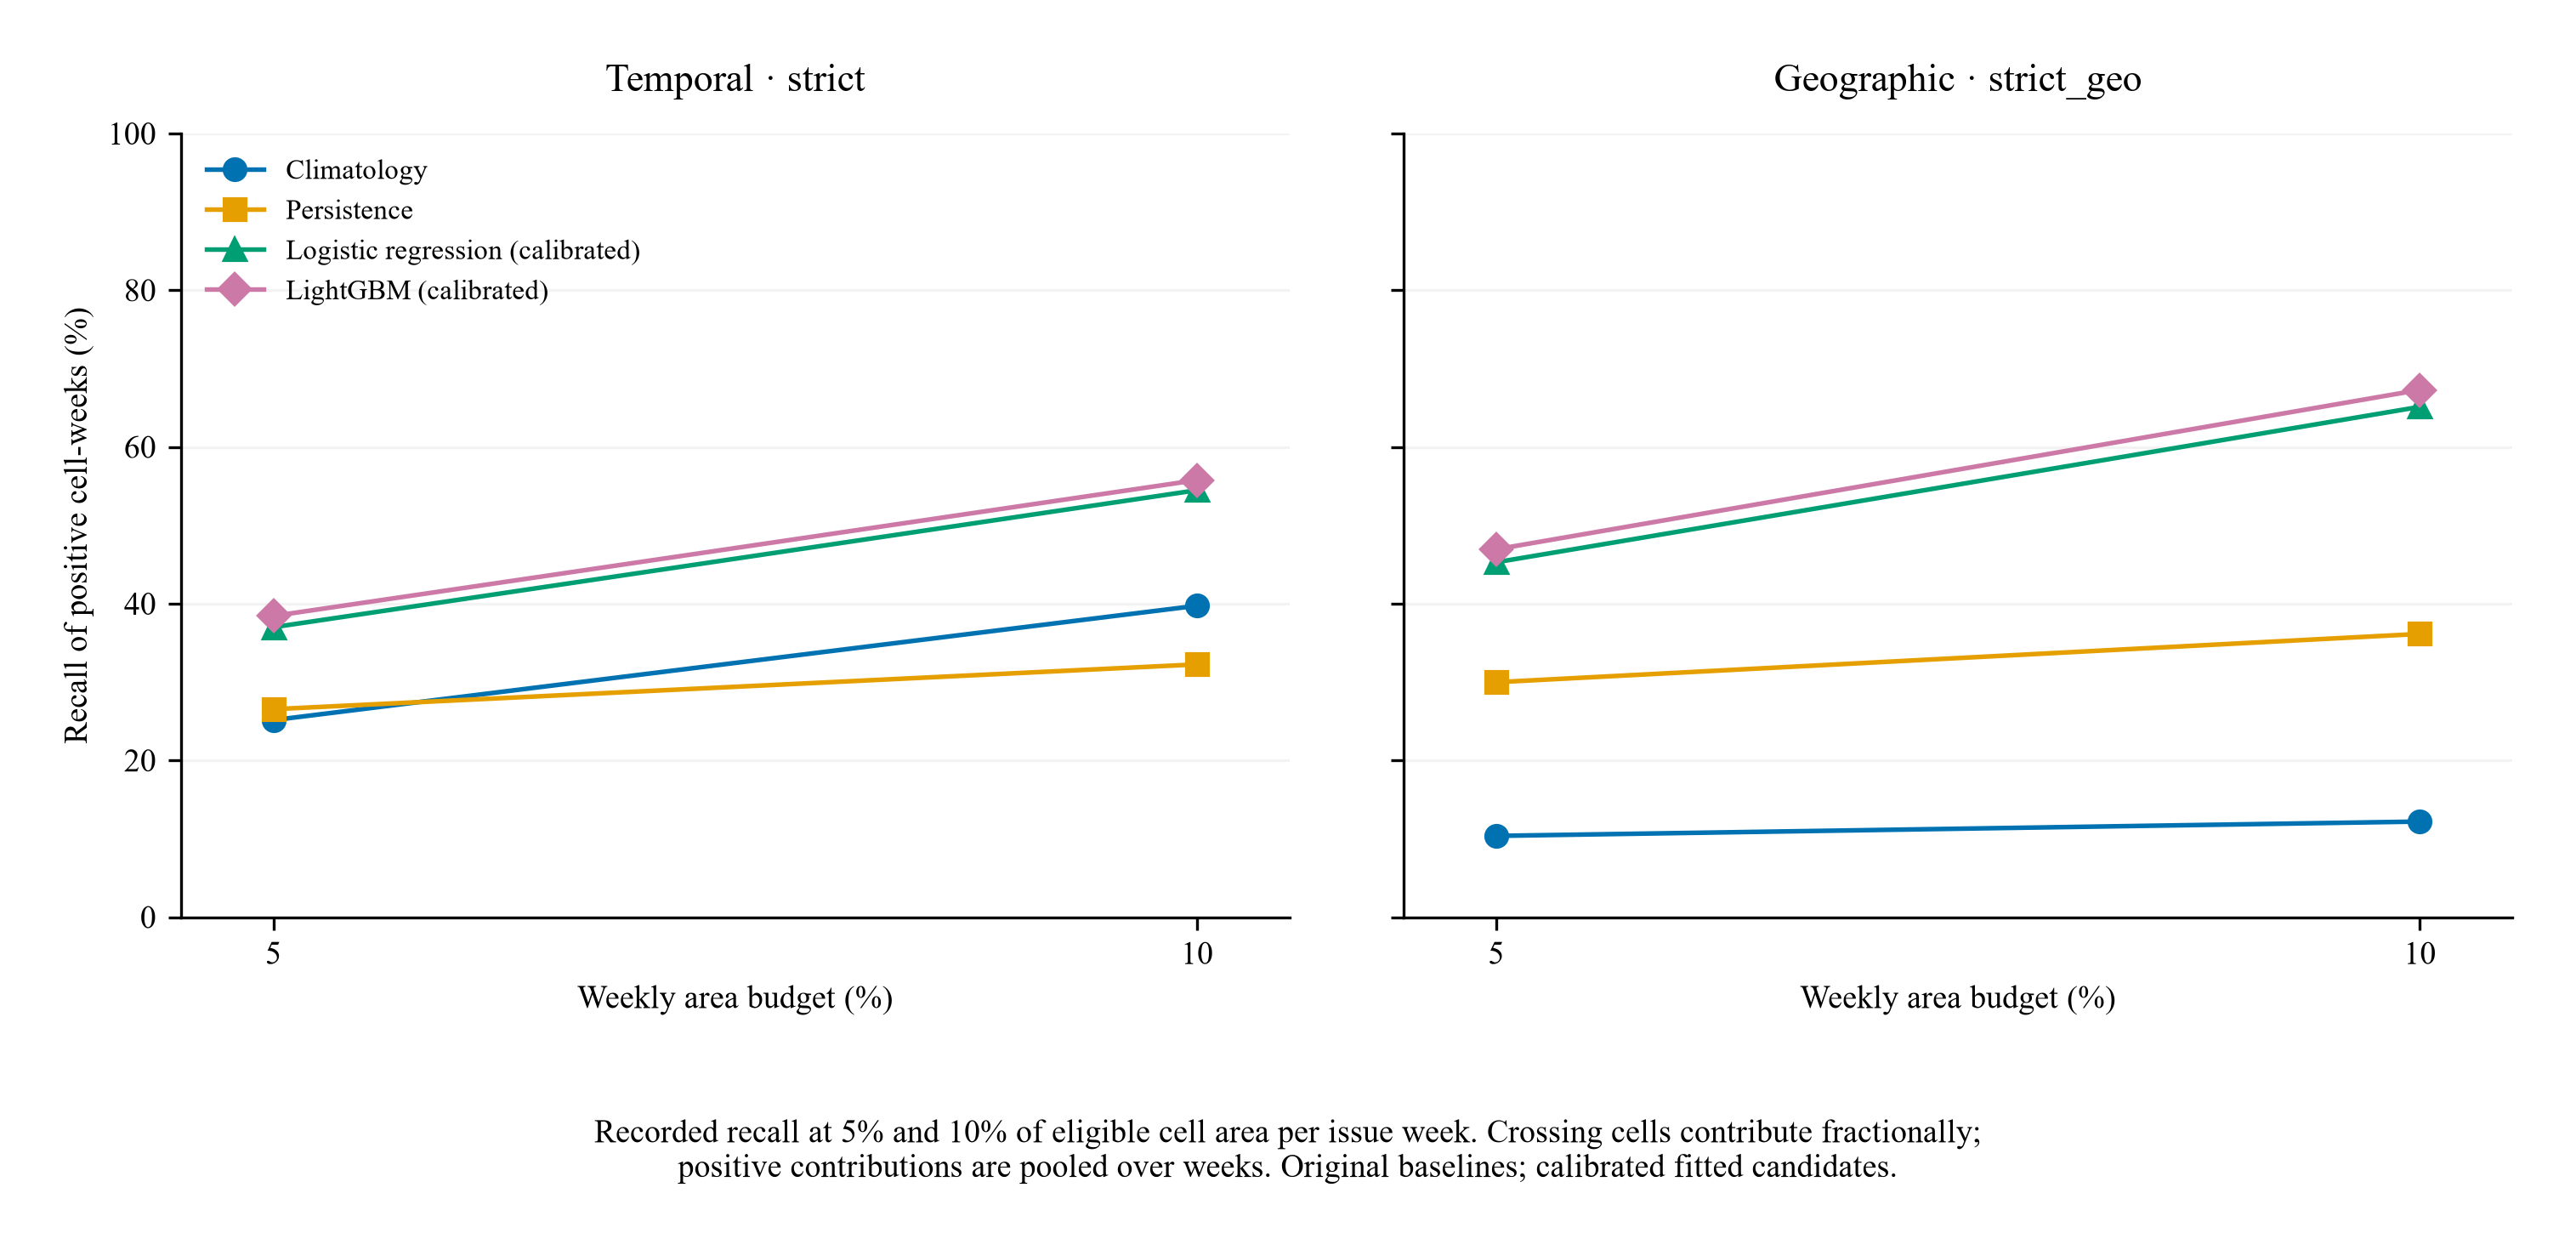

In [6]:
display(
    pd.DataFrame(
        [
            {"Population": population["population"], **value}
            for population in summary["figures"]["area_budget"]["populations"]
            for value in population["values"]
        ]
    )[["Population", "label", "area_budget_pct", "recall"]]
)
show_results_figure("area_budget")

## H2: retrospective minus strict AP

The artifact records a paired confidence interval but no paired point estimate, so the figure
shows the interval alone. An interval containing zero meets the frozen H2 rule; it does not
establish equivalence. Both selected candidates use their recorded calibrated probabilities.

H2: retrospective minus strict AP, calibrated selected candidates. The recorded 95% paired month-block interval is shown without a point: the artifact does not record the paired point estimate. The frozen H2 rule tests whether this interval contains zero; it is not an equivalence test.

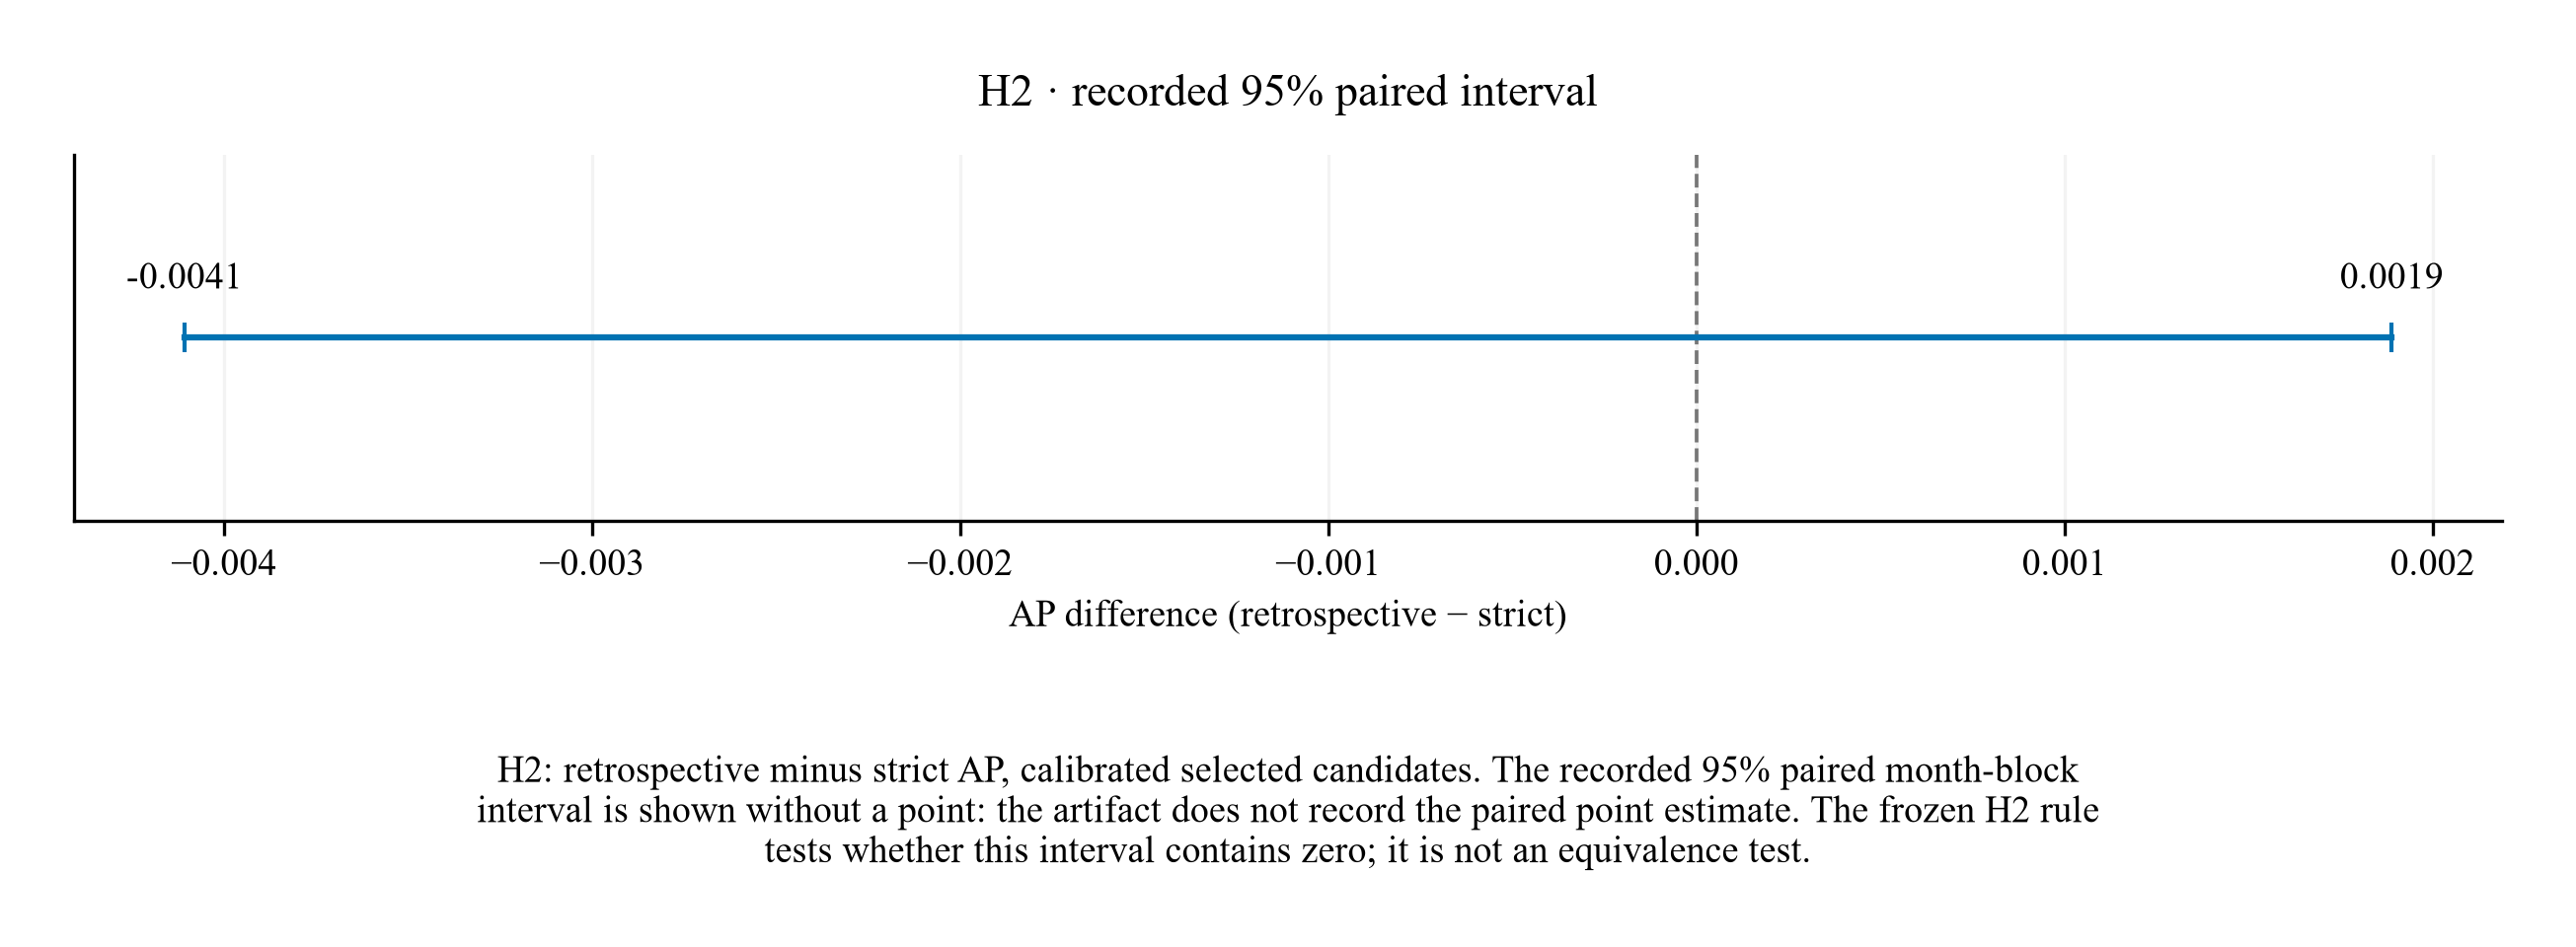

In [7]:
display(Markdown(summary["figures"]["h2"]["caption"]))
show_results_figure("h2")

## A complete high-activity week in 2024

The example week is chosen descriptively from complete 2024 weeks with national prediction
coverage by maximizing primary detections, with earliest-date tie breaking. The probability map
combines the selected temporal model outside held-out blocks and the selected geographic model
inside them. Counts are observed detections per cell, and probabilities retain a fixed 0-1 scale.
No map-derived performance statistic is calculated.

Issue 2024-09-02, target [2024-09-02, 2024-09-09) UTC. Derived example: largest observed detection total among complete 2024 weeks with national prediction coverage; earliest tie. Calibrated strict predictions outside held-out blocks, strict_geo predictions inside them. Right: observed primary detection count per cell (log1p color scale). ADM1 outlines are pinned boundaries. Week selection and counts are descriptive.

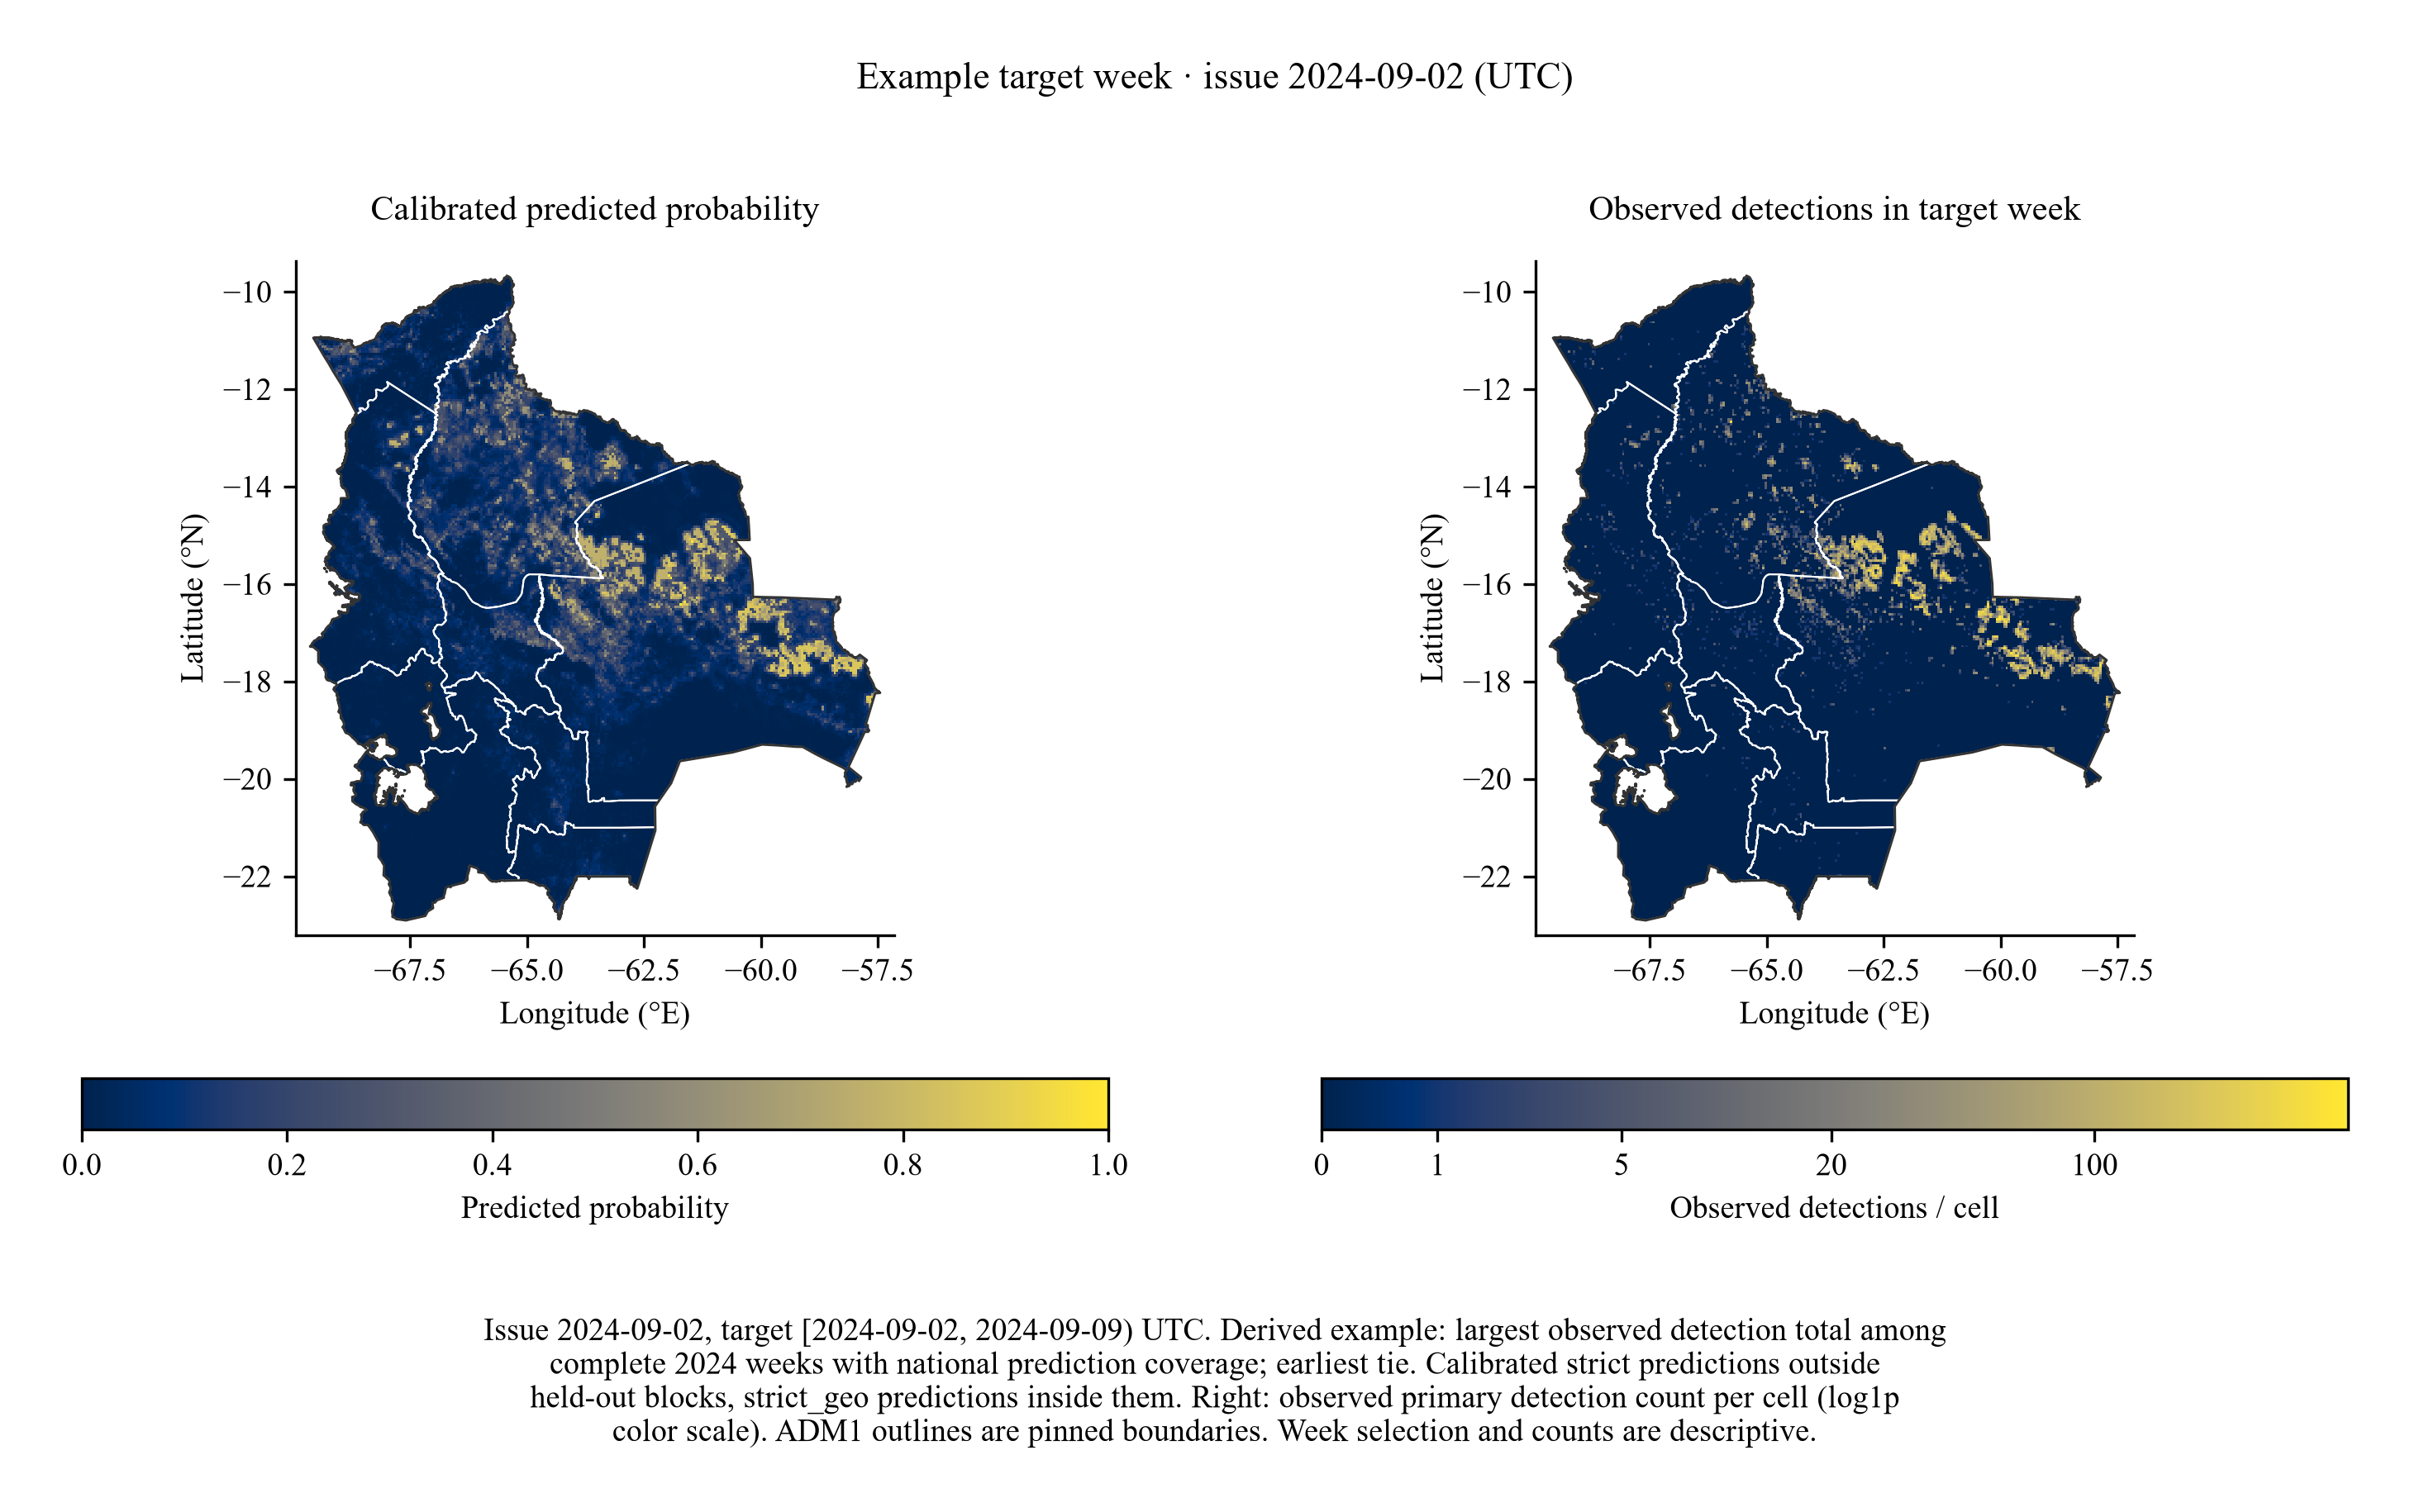

In [8]:
display(Markdown(summary["figures"]["map"]["caption"]))
show_results_figure("map")

## Sensitivity analyses: logged reopenings

The following records are later final-test openings. They test all-confidence labels, exclusion
of low-coverage targets, and removal of neighborhood, climatology or national features. They
are sensitivity analyses of the published benchmark, not additional primary confirmatory tests.
The reason, timestamp and reopening flag are read from each artifact and checked against the
access log. No opening is performed by this notebook.

In [9]:
sensitivity_rows = []
for path in sorted(directory.glob("test_strict_*.json")):
    sensitivity = json.loads(path.read_text(encoding="utf-8"))
    opening = sensitivity["final_test_opening"]
    assert opening in log
    assert opening["reopening"] is True
    name = sensitivity["selected_model"]
    metrics = sensitivity["models"][name]["calibrated"]
    sensitivity_rows.append(
        {
            "Artifact": path.name,
            "Selected": name,
            "Temporal AP": metrics["average_precision"],
            "Brier": metrics["brier_score"],
            "Geographic AP": sensitivity["geographic_holdout"]["models"][
                sensitivity["geographic_holdout"]["selected_model"]
            ]["calibrated"]["average_precision"],
            "Reopening": opening["reopening"],
            "UTC access": opening["timestamp_utc"],
            "Reason": opening["reopen_reason"],
        }
    )
if sensitivity_rows:
    display(pd.DataFrame(sensitivity_rows).set_index("Artifact"))
else:
    display(Markdown("Sensitivity artifacts are pending."))

,Selected,Temporal AP,Brier,Geographic AP,Reopening,UTC access,Reason
Artifact,,,,,,,
test_strict_all_confidence.json,lightgbm_03,0.332164,0.016035,0.384894,True,2026-10-31T11:32:21.625193+00:00,pre-registered sensitivity analysis: all confi...
test_strict_drop_climatology.json,lightgbm_03,0.315992,0.015617,0.387314,True,2026-10-31T13:35:10.379247+00:00,pre-registered sensitivity analysis: ablation ...
test_strict_drop_national.json,lightgbm_14,0.326971,0.015481,0.389078,True,2026-10-31T14:38:48.909295+00:00,pre-registered sensitivity analysis: ablation ...
test_strict_drop_neighborhood.json,lightgbm_03,0.310103,0.015726,0.348085,True,2026-10-31T12:39:49.040694+00:00,pre-registered sensitivity analysis: ablation ...
test_strict_exclude_low_coverage.json,lightgbm_08,0.323393,0.015533,0.383912,True,2026-10-31T15:35:30.829525+00:00,pre-registered sensitivity analysis: exclude l...


## Post-hoc comparison of alternative learners

This exploratory extension was designed after the primary test had been opened. It retains
LightGBM and is separate from the frozen H1/H2 decisions. All values below are read from the
final `artifacts/evaluation/comparison_*.json` records; no models, predictions or metrics are
recomputed and no test opening is performed. The [comparison report](../docs/model-comparison.md)
contains the search spaces, resource costs and complete provenance.

### Validation: selection and calibration years

`comparison_validation.json` supplies `learner.partition.probability` point metrics;
`comparison_bootstrap.json` supplies `partition.learner.probability` AP intervals and paired
AP-difference intervals. Each difference is learner minus recorded LightGBM using the same
probability version, eligible rows and paired calendar-month resamples. Tables separate
partitions and probability versions to keep labels and intervals readable.

Uncalibrated 2021 (`val_select`) AP selected configurations. Isotonic calibration was fitted
on 2022 (`val_calib`) only after choices were frozen. Calibrated 2022 diagnostics reuse those
fitting labels and are not an independent calibration assessment. Intervals condition on
fixed fitted models and calibrators, omitting training and search uncertainty.

In [10]:
def comparison_record(name):
    return json.loads((directory / f"comparison_{name}.json").read_text(encoding="utf-8"))


def interval_text(interval, signed=False):
    if interval is None:
        return "Reference"
    if interval["lower"] is None or interval["upper"] is None:
        return interval.get("reason") or "Undefined"
    spec = "+.6f" if signed else ".6f"
    return f"[{interval['lower']:{spec}}, {interval['upper']:{spec}}]"


def comparison_table(rows):
    display(
        pd.DataFrame(rows)
        .set_index("Model")
        .style.format(precision=6)
        .set_properties(**{"white-space": "normal"})
    )


comparison_validation = comparison_record("validation")
comparison_bootstrap = comparison_record("bootstrap")
comparison_selection = comparison_record("selection")
comparison_labels = {
    "lightgbm": "LightGBM (recorded)",
    "logistic_regression": "Logistic regression (recorded)",
    "xgboost": "XGBoost hist",
    "catboost": "CatBoost",
    "spatial_cnn": "Spatial CNN",
}
validation_stages = [
    ("val_select", "uncalibrated", "2021 selection: uncalibrated"),
    ("val_calib", "uncalibrated", "2022 calibration year: uncalibrated"),
    ("val_calib", "calibrated", "2022 calibration year: calibrated"),
]
for partition, probability, title in validation_stages:
    display(Markdown(f"**Post-hoc validation: {title}**"))
    validation_rows = []
    for learner, label in comparison_labels.items():
        values = comparison_validation[learner][partition][probability]
        intervals = comparison_bootstrap[partition][learner][probability]
        paired = intervals["paired_difference"]
        validation_rows.append(
            {
                "Model": label,
                "AP [95% CI]": (
                    f"{values['average_precision']:.6f} "
                    + interval_text(intervals["metrics"]["average_precision"])
                ),
                "Paired AP CI vs LightGBM (95%)": interval_text(
                    paired["average_precision"] if paired is not None else None,
                    signed=True,
                ),
            }
        )
    comparison_table(validation_rows)
    display(
        Markdown(
            f"Recorded bootstrap: {intervals['replicates']} replicates, "
            f"{intervals['blocks']} observed calendar-month blocks; "
            f"seed {intervals['seed']}."
        )
    )

comparison_diagnostics = {
    key: metric_labels[key]
    for key in (
        "roc_auc",
        "brier_score",
        "log_loss",
        "expected_calibration_error",
        "recall_at_area_budget_5pct",
        "recall_at_area_budget_10pct",
    )
}
display(Markdown("**Post-hoc validation: 2022 calibrated secondary metrics**"))
comparison_table(
    [
        {
            "Model": label,
            **{
                title: comparison_validation[learner]["val_calib"]["calibrated"][key]
                for key, title in comparison_diagnostics.items()
            },
        }
        for learner, label in comparison_labels.items()
    ]
)
display(Markdown("**Frozen validation decision: `comparison_selection.json`**"))
display(Markdown("Decision basis: " + comparison_selection["decision_basis"]))
display(Markdown(comparison_selection["decision"]))
display(Markdown(comparison_selection["future_evaluation"]))
for limitation in comparison_selection["limitations"]:
    display(Markdown("- " + limitation))

**Post-hoc validation: 2021 selection: uncalibrated**

,AP [95% CI],Paired AP CI vs LightGBM (95%)
Model,,
LightGBM (recorded),"0.346855 [0.206830, 0.399072]",Reference
Logistic regression (recorded),"0.326496 [0.182567, 0.381861]","[-0.031044, -0.014742]"
XGBoost hist,"0.345404 [0.206813, 0.399745]","[-0.003104, +0.001201]"
CatBoost,"0.348614 [0.211545, 0.404176]","[-0.000305, +0.005706]"
Spatial CNN,"0.350462 [0.211483, 0.404733]","[+0.000270, +0.006222]"


Recorded bootstrap: 500 replicates, 11 observed calendar-month blocks; seed 7.

**Post-hoc validation: 2022 calibration year: uncalibrated**

,AP [95% CI],Paired AP CI vs LightGBM (95%)
Model,,
LightGBM (recorded),"0.319169 [0.227738, 0.374718]",Reference
Logistic regression (recorded),"0.286024 [0.195610, 0.344419]","[-0.037173, -0.010962]"
XGBoost hist,"0.313248 [0.225110, 0.368256]","[-0.009516, -0.000078]"
CatBoost,"0.323372 [0.234115, 0.382338]","[-0.001047, +0.011021]"
Spatial CNN,"0.317202 [0.231040, 0.371167]","[-0.006205, +0.003870]"


...

Retain the published LightGBM model; no alternative has a validation AP gain with a paired interval excluding zero.

CatBoost is a candidate for a future pre-registered comparison on a new untouched holdout.

- Calibration-year metrics reuse isotonic fitting labels

- Bootstrap fixes fitted learners and calibrators; it excludes search and initialization uncertainty

- The primary test had already been opened before the private study and this repository rerun

### CatBoost determinism and reproduction

The final audit in `comparison_determinism_audit.json` checks source/rerun array,
trial-parameter and binary identity. `comparison_reproduction.json` records the selected
trials and paired-interval conclusion. Its source-study values below are reproduction
comparators; the validation tables above use this repository's final rerun values.

In [11]:
comparison_audit = comparison_record("determinism_audit")
comparison_reproduction = comparison_record("reproduction")
catboost_reproduction = comparison_reproduction["catboost_selection"]
display(Markdown(comparison_audit["interpretation"]))
display(Markdown(f"[CatBoost GPU determinism documentation]({comparison_audit['reference']})"))
print("Training/selection arrays identical:", all(
    item["identical"] for item in comparison_audit["array_identity"].values()
))
print("Trial parameters identical:", all(
    item["identical"] for item in comparison_audit["trial_parameters"].values()
))
print("CatBoost binary identical:", comparison_audit["catboost_binary_identical"])
print("Source selected trial:", catboost_reproduction["source_trial"])
print("Rerun selected trial:", catboost_reproduction["rerun_trial"])
print("Paired conclusion changed:", catboost_reproduction["paired_conclusion_changed"])
comparison_table(
    [
        {
            "Model": label,
            "2022 calibrated paired AP CI vs LightGBM (95%)": interval_text(
                catboost_reproduction[key], signed=True
            ),
        }
        for label, key in (
            ("CatBoost source study", "source_paired_calibrated_ap_interval"),
            ("CatBoost repository rerun", "rerun_paired_calibrated_ap_interval"),
        )
    ]
)
comparison_cpu = comparison_record("cpu_check")
display(Markdown("**Separate CPU audit: `comparison_cpu_check.json`**"))
display(Markdown(comparison_cpu["scope"]))
print("CPU refit completed:", comparison_cpu["completed"])
print("Fixed GPU-selected tree count:", comparison_cpu["fixed_gpu_tree_count"])
print("CPU validation-selection AP:", f"{comparison_cpu['val_select']['average_precision']:.6f}")
print("Saved-model prediction roundtrip exact:", comparison_cpu["prediction_roundtrip_exact"])
display(
    Markdown(
        "A single CPU refit does not establish between-fit identity. It was not calibrated, "
        "scored on test or used to select a learner; the frozen GPU search remains the reference."
    )
)

Different GPU scores with identical data, parameters and binary are consistent with documented reduction nondeterminism; the frozen search is unchanged. Any observed data or binary differences are reported separately.

[CatBoost GPU determinism documentation](https://catboost.ai/docs/en/features/training-on-gpu)

Training/selection arrays identical: True
Trial parameters identical: True
CatBoost binary identical: True
Source selected trial: 1
Rerun selected trial: 19
Paired conclusion changed: False


,2022 calibrated paired AP CI vs LightGBM (95%)
Model,
CatBoost source study,"[-0.001438, +0.010196]"
CatBoost repository rerun,"[-0.001901, +0.009632]"


**Separate CPU audit: `comparison_cpu_check.json`**

One CPU refit at the GPU-selected tree count; no retuning or test scoring

CPU refit completed: True
Fixed GPU-selected tree count: 200
CPU validation-selection AP: 0.347266
Saved-model prediction roundtrip exact: True


A single CPU refit does not establish between-fit identity. It was not calibrated, scored on test or used to select a learner; the frozen GPU search remains the reference.

### Exploratory post-hoc test: previously opened 2023-2025 holdout

These descriptive temporal scores are **post-hoc exploratory results**, not confirmatory
evidence or a new holdout. Test scores did not select models, calibrators, configurations or
the recommendation. Geographic holdout scoring is outside this comparison.

`comparison_test.json` supplies `models.learner.probability` metrics and the logged opening.
AP is shown for both probability versions; the secondary metrics use calibrated probabilities.
The notebook reads the existing opening and checks it against `final_test_log.json`.

In [12]:
comparison_test = comparison_record("test")
comparison_opening = comparison_test["opening"]
assert comparison_opening in log
assert comparison_opening["type"] == "post_hoc_comparison"
assert (
    comparison_opening["comparison_selection_sha256"]
    == sha256_file(directory / "comparison_selection.json")
)
display(Markdown(f"**{comparison_test['status']}**"))
print("Recorded exploratory opening (UTC):", comparison_opening["timestamp_utc"])
print("Reason:", comparison_opening["reason"])
print("Eligible temporal cell-weeks:", f"{comparison_test['rows']:,}")
print("Positives:", f"{comparison_test['positives']:,}")
display(Markdown("**Exploratory post-hoc test: AP, 2023-2025**"))
comparison_table(
    [
        {
            "Model": label,
            "Uncalibrated AP": comparison_test["models"][learner]["uncalibrated"][
                "average_precision"
            ],
            "Calibrated AP": comparison_test["models"][learner]["calibrated"][
                "average_precision"
            ],
        }
        for learner, label in comparison_labels.items()
    ]
)
display(Markdown("**Exploratory post-hoc test: calibrated secondary metrics, 2023-2025**"))
comparison_table(
    [
        {
            "Model": label,
            **{
                title: comparison_test["models"][learner]["calibrated"][key]
                for key, title in comparison_diagnostics.items()
            },
        }
        for learner, label in comparison_labels.items()
    ]
)

**POST-HOC EXPLORATORY; NOT A NEW HOLDOUT; NEVER USED FOR CHOICES**

Recorded exploratory opening (UTC): 2026-10-31T19:36:43.128562+00:00
Reason: post-hoc exploratory comparison of alternative learners; does not change the reported model
Eligible temporal cell-weeks: 3,127,636
Positives: 61,119


**Exploratory post-hoc test: AP, 2023-2025**

,Uncalibrated AP,Calibrated AP
Model,,
LightGBM (recorded),0.327991,0.323393
Logistic regression (recorded),0.297390,0.293042
XGBoost hist,0.323951,0.318529
CatBoost,0.336571,0.330587
Spatial CNN,0.323695,0.318591


**Exploratory post-hoc test: calibrated secondary metrics, 2023-2025**

,ROC AUC,Brier,Log loss,ECE,Recall 5%,Recall 10%
Model,,,,,,
LightGBM (recorded),0.927621,0.015533,0.062067,0.003132,0.384318,0.557699
Logistic regression (recorded),0.923338,0.015900,0.063911,0.003878,0.369967,0.544833
XGBoost hist,0.926856,0.015570,0.062220,0.003249,0.383617,0.557492
CatBoost,0.928048,0.015483,0.062047,0.003805,0.386857,0.561787
Spatial CNN,0.929615,0.015554,0.061903,0.003246,0.386150,0.567649
